In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

countries_df = pd.read_csv("/content/countries.csv")
events_df = pd.read_csv("/content/events.csv")
products_df = pd.read_csv("/content/products.csv")

In [ ]:
print(countries_df.columns)
print(events_df.columns)
print(products_df.columns)

Index(['name', 'alpha-2', 'alpha-3', 'region', 'sub-region'], dtype='object')
Index(['Order ID', 'Order Date', 'Ship Date', 'Order Priority', 'Country Code',
       'Product ID', 'Sales Channel', 'Units Sold', 'Unit Price', 'Unit Cost'],
      dtype='object')
Index(['id', 'item_type'], dtype='object')


In [ ]:
events_merge = events_df.copy()
countries_merge = countries_df.copy()
products_merge = products_df.copy()

countries_merge = countries_merge.rename(
    columns={
        "alpha-3": "Country Code",
        "name": "Country"})

products_merge = products_merge.rename(
    columns={
        "id": "Product ID" })

events_merge["Country Code"] = (
    events_merge["Country Code"]
    .astype("string")
    .str.strip()
    .str.upper())

countries_merge["Country Code"] = (
    countries_merge["Country Code"]
    .astype("string")
    .str.strip()
    .str.upper())

events_merge["Product ID"] = (
    events_merge["Product ID"]
    .astype("string")
    .str.strip())

products_merge["Product ID"] = (
    products_merge["Product ID"]
    .astype("string")
    .str.strip())

df = events_merge.merge(
    countries_merge[
        ["Country Code", "Country", "region", "sub-region"]],
    on="Country Code",
    how="left")

df = df.merge(
    products_merge[
        ["Product ID", "item_type"]],
    on="Product ID",
    how="left")


In [ ]:
print(df.columns)
print(df.shape)
print(df.isna().sum())

Index(['Order ID', 'Order Date', 'Ship Date', 'Order Priority', 'Country Code',
       'Product ID', 'Sales Channel', 'Units Sold', 'Unit Price', 'Unit Cost',
       'Country', 'region', 'sub-region', 'item_type'],
      dtype='object')
(1330, 14)
Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
Country           82
region            82
sub-region        82
item_type          0
dtype: int64


In [ ]:
print(df.isna().sum() / df.shape[0] * 100)

Order ID          0.000000
Order Date        0.000000
Ship Date         0.000000
Order Priority    0.000000
Country Code      6.165414
Product ID        0.000000
Sales Channel     0.000000
Units Sold        0.150376
Unit Price        0.000000
Unit Cost         0.000000
Country           6.165414
region            6.165414
sub-region        6.165414
item_type         0.000000
dtype: float64


In [ ]:
df[df["Units Sold"].isna()]

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,Country,region,sub-region,item_type
183,217165648,5/20/2014,6/8/2014,M,ESP,8875,Offline,NaN,421.89,364.69,Spain,Europe,Southern Europe,Meat
319,309655511,5/5/2014,5/21/2014,C,HRV,3127,Offline,NaN,81.73,56.67,Croatia,Europe,Southern Europe,Personal Care


In [ ]:

df = df.dropna(subset=["Units Sold"])
print(df["Units Sold"].isna().sum())
print(df.shape)

0
(1328, 14)


The units_sold column contained 2 missing values. These rows were removed because, without information about the number of units sold, it is impossible to correctly calculate the key metrics: revenue, total cost, and profit.  Since the missing values account for only 2 rows out of 1330, or approximately 0.15% of the data, removing them will not have a significant impact on the overall conclusions.

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1328 non-null   int64         
 1   Order Date      1328 non-null   datetime64[ns]
 2   Ship Date       1328 non-null   datetime64[ns]
 3   Order Priority  1328 non-null   object        
 4   Country Code    1246 non-null   string        
 5   Product ID      1328 non-null   string        
 6   Sales Channel   1328 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1328 non-null   float64       
 9   Unit Cost       1328 non-null   float64       
 10  Country         1246 non-null   object        
 11  region          1246 non-null   object        
 12  sub-region      1246 non-null   object        
 13  item_type       1328 non-null   object        
dtypes: datetime64[ns](2), float64(3), int64(1), object(6), string

In [ ]:
df.columns = (df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("-", "_"))

In [ ]:
print(df.columns)

Index(['order_id', 'order_date', 'ship_date', 'order_priority', 'country_code',
       'product_id', 'sales_channel', 'units_sold', 'unit_price', 'unit_cost',
       'country', 'region', 'sub_region', 'item_type'],
      dtype='object')


In [ ]:
duplicate_rows = df.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())


0       False
1       False
2       False
3       False
4       False
        ...  
1325    False
1326    False
1327    False
1328    False
1329    False
Length: 1328, dtype: bool
0


#Data analysis and visualization.

###Creating Sales Indicators and Key Metrics

In [ ]:
df.loc[:, "country"] = df["country"].fillna("Unknown")
df.loc[:, "region"] = df["region"].fillna("Unknown")
df.loc[:, "sub_region"] = df["sub_region"].fillna("Unknown")

df.loc[:, "revenue"] = (df["units_sold"] * df["unit_price"])
df.loc[:, "total_cost"] = (df["units_sold"] * df["unit_cost"])
df.loc[:, "profit"] = (df["revenue"] - df["total_cost"])


total_orders = df["order_id"].nunique()
total_revenue = df["revenue"].sum()
total_cost = df["total_cost"].sum()
total_profit = df["profit"].sum()
total_units_sold = df["units_sold"].sum()

countries_covered = df.loc[df["country"] != "Unknown", "country"].nunique()

regions_covered = df.loc[df["region"] != "Unknown", "region"].nunique()

order_summary = (df.groupby("order_id", as_index=False).agg(order_revenue=("revenue", "sum")))

average_order_value = order_summary["order_revenue"].mean()
profit_margin = (total_profit / total_revenue) * 100

key_metrics = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Profit Margin",
        "Units Sold",
        "Countries Covered",
        "Regions Covered",
        "Average Order Value"
    ],
    "Value": [
        f"{total_orders:,}",
        f"${total_revenue:,.2f}",
        f"${total_cost:,.2f}",
        f"${total_profit:,.2f}",
        f"{profit_margin:.2f}%",
        f"{total_units_sold:,.0f}",
        f"{countries_covered:,}",
        f"{regions_covered:,}",
        f"${average_order_value:,.2f}"
    ]
})
display(key_metrics)

,Metric,Value
0,Total Orders,"1,328"
1,Total Revenue,"$1,702,129,408.21"
2,Total Cost,"$1,200,694,949.21"
3,Total Profit,"$501,434,459.00"
4,Profit Margin,29.46%
5,Units Sold,"6,576,524"
6,Countries Covered,45
7,Regions Covered,2
8,Average Order Value,"$1,281,723.95"


Analysis by Product Category

In [ ]:
product_summary = (
    df.groupby("item_type", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        profit=("profit", "sum"),
        units_sold=("units_sold", "sum"),
        orders=("order_id", "nunique")
    ).sort_values("profit", ascending=False))
display(product_summary)

,item_type,revenue,total_cost,profit,units_sold,orders
4,Cosmetics,2.331548e+08,1.404315e+08,92723306.17,533291.0,114
8,Office Supplies,4.022140e+08,3.242368e+08,77977176.25,617641.0,123
6,Household,2.942052e+08,2.212427e+08,72962466.77,440249.0,97
0,Baby Food,1.436476e+08,8.970659e+07,53940997.16,562706.0,112
3,Clothes,6.462655e+07,2.119524e+07,43431314.40,591385.0,105
2,Cereal,9.579140e+07,5.453637e+07,41255034.15,465685.0,103
11,Vegetables,8.974673e+07,5.297073e+07,36776002.72,582544.0,114
7,Meat,2.237620e+08,1.934243e+08,30337736.00,530380.0,110
10,Snacks,7.478861e+07,4.776119e+07,27027422.40,490160.0,103
9,Personal Care,4.557902e+07,3.160361e+07,13975410.68,557678.0,114


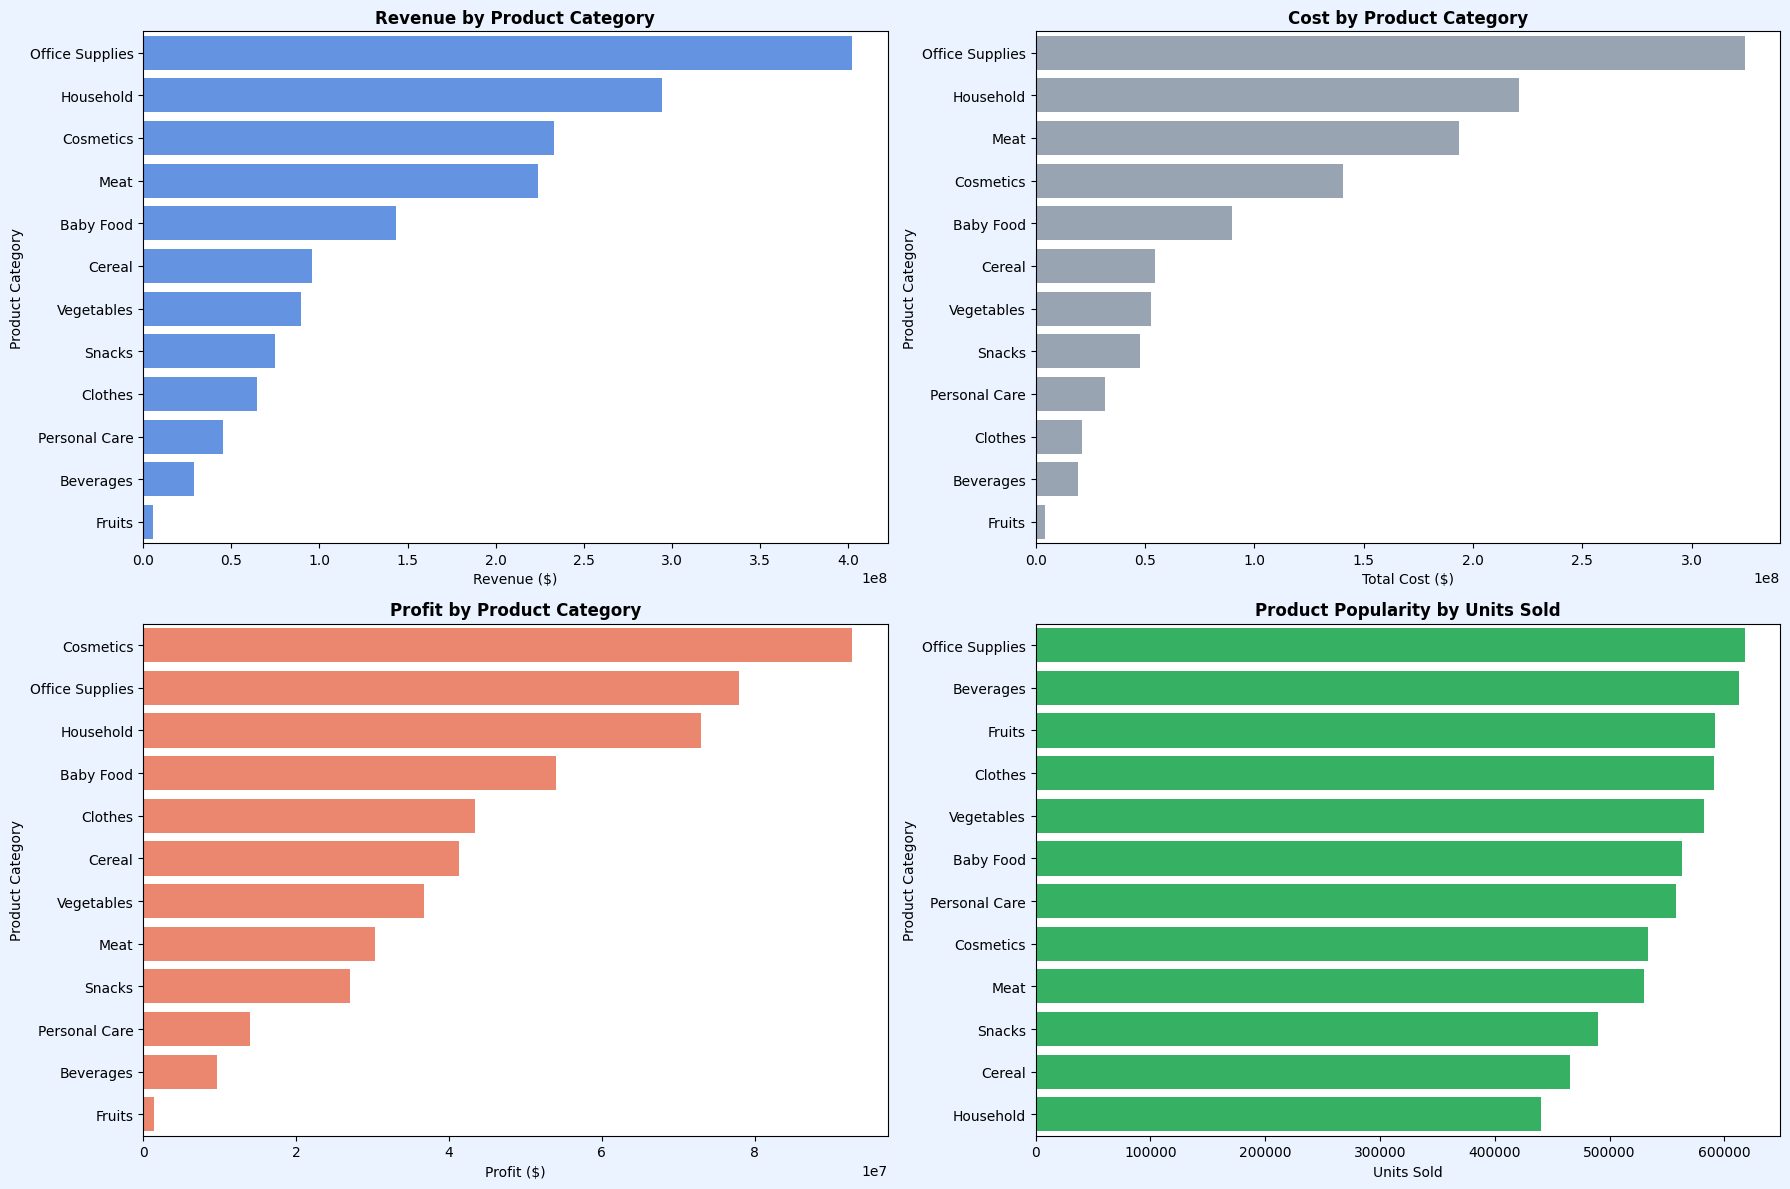

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor("#EAF3FF")

sns.barplot(
    data=product_summary.sort_values("revenue", ascending=False),
    x="revenue",
    y="item_type",
    color="#4F8EF7",
    ax=ax[0, 0])

ax[0, 0].set_title("Revenue by Product Category", fontweight="bold")
ax[0, 0].set_xlabel("Revenue ($)")
ax[0, 0].set_ylabel("Product Category")

sns.barplot(
    data=product_summary.sort_values("total_cost", ascending=False),
    x="total_cost",
    y="item_type",
    color="#94A3B8",
    ax=ax[0, 1])

ax[0, 1].set_title("Cost by Product Category", fontweight="bold")
ax[0, 1].set_xlabel("Total Cost ($)")
ax[0, 1].set_ylabel("Product Category")

sns.barplot(
    data=product_summary.sort_values("profit", ascending=False),
    x="profit",
    y="item_type",
    color="#FF7A59",
    ax=ax[1, 0])

ax[1, 0].set_title("Profit by Product Category", fontweight="bold")
ax[1, 0].set_xlabel("Profit ($)")
ax[1, 0].set_ylabel("Product Category")

sns.barplot(
    data=product_summary.sort_values("units_sold", ascending=False),
    x="units_sold",
    y="item_type",
    color="#22C55E",
    ax=ax[1, 1])

ax[1, 1].set_title("Product Popularity by Units Sold", fontweight="bold")
ax[1, 1].set_xlabel("Units Sold")
ax[1, 1].set_ylabel("Product Category")

plt.tight_layout()
plt.show()

Office Supplies leads in revenue and the number of units sold. However, Cosmetics ranks first in profit, indicating higher profitability for this category. Fruits generates low revenue and profit, although it ranks relatively high in the number of units sold

###Geographic Analysis: Regions and Countries

In [ ]:
geo_data = df[
    (df["country"] != "Unknown") &
    (df["region"] != "Unknown")]

region_summary = (
    geo_data.groupby("region", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        profit=("profit", "sum"),
        units_sold=("units_sold", "sum"),
        orders=("order_id", "nunique")
    ).sort_values("profit", ascending=False))


country_summary = (
    geo_data.groupby("country", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        profit=("profit", "sum"),
        units_sold=("units_sold", "sum"),
        orders=("order_id", "nunique"))
    .sort_values("revenue", ascending=False))

display(region_summary)
display(country_summary.head(10))

,region,revenue,total_cost,profit,units_sold,orders
1,Europe,1.505653e+09,1.057096e+09,4.485568e+08,5761244.0,1164
0,Asia,9.333089e+07,6.817863e+07,2.515225e+07,410427.0,82


,country,revenue,total_cost,profit,units_sold,orders
10,Czech Republic,53543932.14,39908338.36,13635593.78,142446.0,31
43,Ukraine,53252317.54,38447391.80,14804925.74,164577.0,33
6,Bosnia and Herzegovina,50117508.49,36859905.72,13257602.77,153545.0,33
26,Macedonia,49222085.25,35537985.30,13684099.95,203078.0,32
36,San Marino,47883708.48,34090715.67,13792992.81,192228.0,40
1,Andorra,47756693.17,32346656.54,15410036.63,185686.0,40
33,Portugal,47172189.84,35826782.25,11345407.59,124825.0,25
27,Malta,47145320.81,32535192.93,14610127.88,173641.0,32
35,Russia,46051659.81,32783977.17,13267682.64,165954.0,32
38,Slovakia,42940998.32,30888208.29,12052790.03,131540.0,30


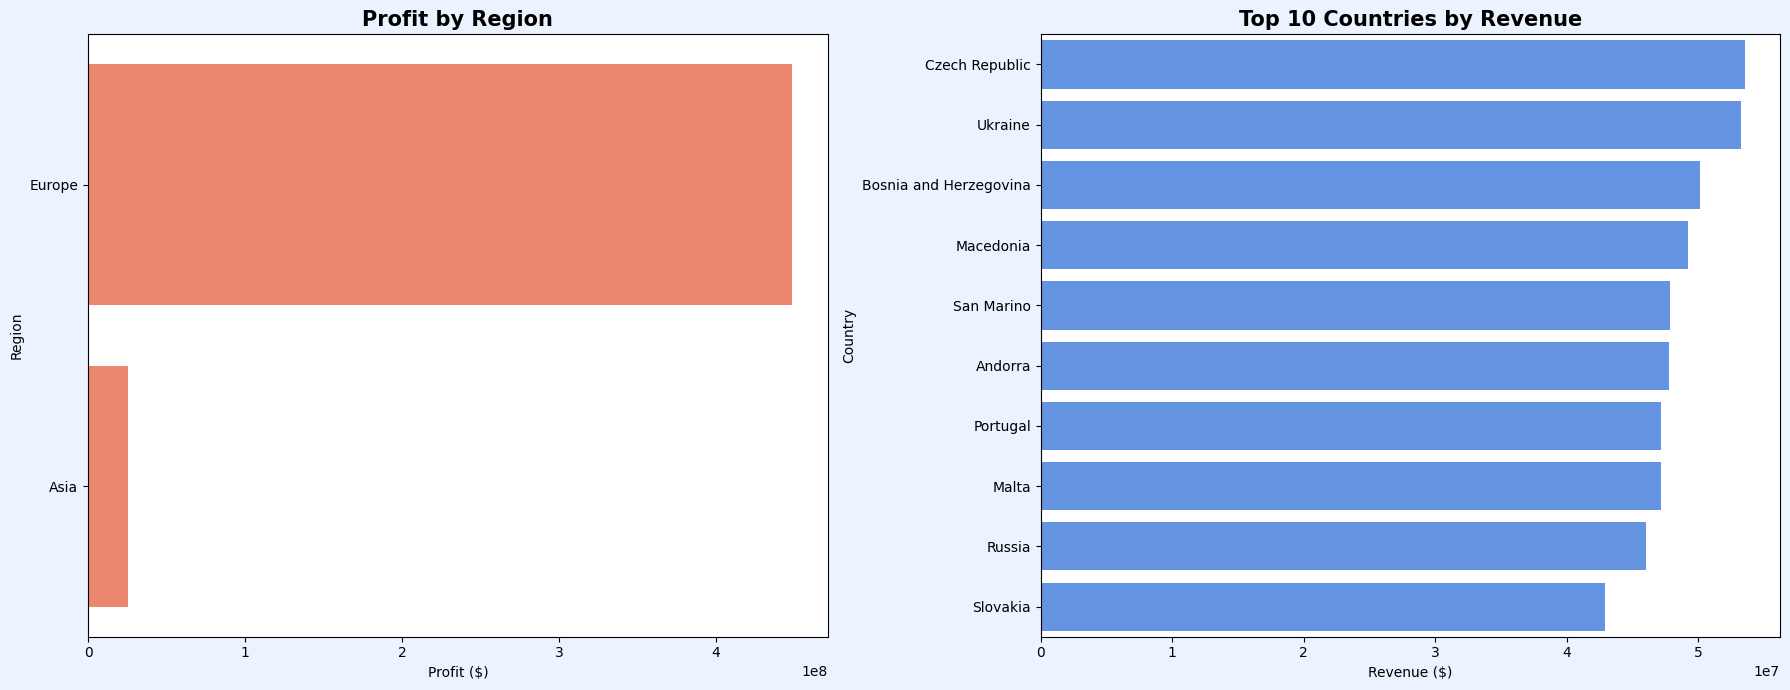

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor("#EAF3FF")

sns.barplot(
    data=region_summary,
    x="profit",
    y="region",
    color="#FF7A59",
    ax=axes[0]
)

axes[0].set_title("Profit by Region", fontsize=15, fontweight="bold")
axes[0].set_xlabel("Profit ($)")
axes[0].set_ylabel("Region")

sns.barplot(
    data=country_summary.head(10),
    x="revenue",
    y="country",
    color="#4F8EF7",
    ax=axes[1]
)

axes[1].set_title("Top 10 Countries by Revenue", fontsize=15, fontweight="bold")
axes[1].set_xlabel("Revenue ($)")
axes[1].set_ylabel("Country")

plt.tight_layout()
plt.show()

In terms of profit, Europe is well ahead of Asia. Czechia is the most profitable country.

```
# Code format selected
```



###Analysis by Sales Channel: Online / Offline

In [ ]:
print(df["sales_channel"].value_counts(dropna=False))

sales_channel
Offline    665
Online     660
online       3
Name: count, dtype: int64


In [ ]:
df.loc[:, "sales_channel"] = (
    df["sales_channel"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "online": "Online",
        "offline": "Offline"
    }))

In [ ]:
channel_summary = (
    df.groupby("sales_channel", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        profit=("profit", "sum"),
        units_sold=("units_sold", "sum"),
        orders=("order_id", "nunique")
).sort_values("profit", ascending=False))

display(channel_summary)

,sales_channel,revenue,total_cost,profit,units_sold,orders
0,Offline,8.717606e+08,6.182941e+08,2.534665e+08,3320363.0,665
1,Online,8.303688e+08,5.824008e+08,2.479679e+08,3256161.0,663


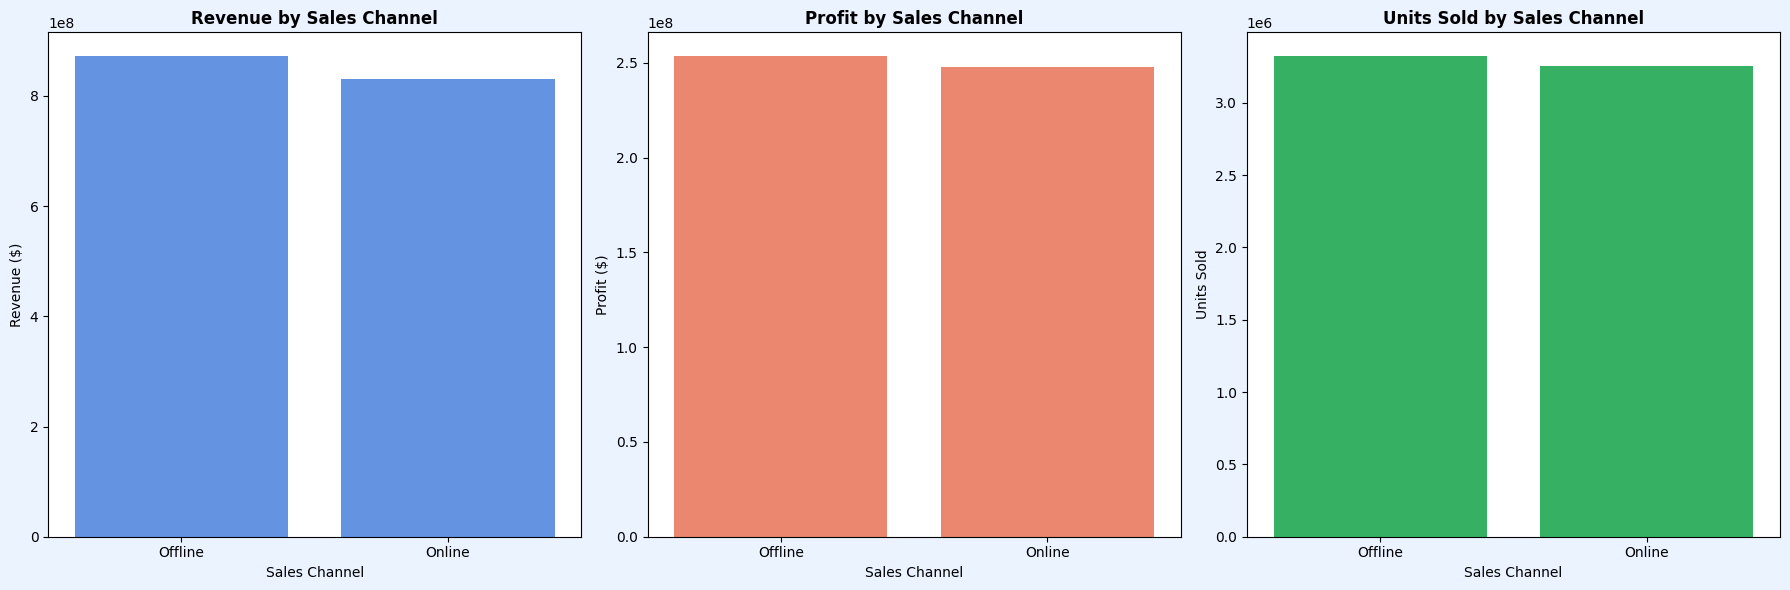

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor("#EAF3FF")

sns.barplot(
    data=channel_summary,
    x="sales_channel",
    y="revenue",
    color="#4F8EF7",
    ax=axes[0])

axes[0].set_title("Revenue by Sales Channel", fontweight="bold")
axes[0].set_xlabel("Sales Channel")
axes[0].set_ylabel("Revenue ($)")

sns.barplot(
    data=channel_summary,
    x="sales_channel",
    y="profit",
    color="#FF7A59",
    ax=axes[1])

axes[1].set_title("Profit by Sales Channel", fontweight="bold")
axes[1].set_xlabel("Sales Channel")
axes[1].set_ylabel("Profit ($)")


sns.barplot(
    data=channel_summary,
    x="sales_channel",
    y="units_sold",
    color="#22C55E",
    ax=axes[2])

axes[2].set_title("Units Sold by Sales Channel", fontweight="bold")
axes[2].set_xlabel("Sales Channel")
axes[2].set_ylabel("Units Sold")

plt.tight_layout()
plt.show()

The offline channel is slightly more effective across all three metrics: it has higher revenue, profit, and units sold. At the same time, the difference between offline and online sales is relatively small, so both channels are important to the business

###Drawing Key Conclusions

In [ ]:
best_product_profit = product_summary.iloc[0]
most_popular_product = product_summary.sort_values(
    "units_sold", ascending=False).iloc[0]

best_region = region_summary.iloc[0]
top_country = country_summary.iloc[0]
best_channel = channel_summary.iloc[0]

print(
    f"Most profitable product category: "
    f"{best_product_profit['item_type']} "
    f"(${best_product_profit['profit']:,.2f})")

print(
    f"Most popular product category: "
    f"{most_popular_product['item_type']} "
    f"({most_popular_product['units_sold']:,.0f} units sold)")

print(
    f"Most profitable region: "
    f"{best_region['region']} "
    f"(${best_region['profit']:,.2f})")

print(
    f"Country with the highest revenue: "
    f"{top_country['country']} "
    f"(${top_country['revenue']:,.2f})")

print(
    f"Most profitable sales channel: "
    f"{best_channel['sales_channel']} "
    f"(${best_channel['profit']:,.2f})")

Most profitable product category: Cosmetics ($92,723,306.17)
Most popular product category: Office Supplies (617,641 units sold)
Most profitable region: Europe ($448,556,782.11)
Country with the highest revenue: Czech Republic ($53,543,932.14)
Most profitable sales channel: Offline ($253,466,518.81)


###Shipping Interval by Product Category

In [ ]:
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days


In [ ]:
shipping_data = df[df["shipping_days"].notna() & (df["shipping_days"] >= 0)]

In [ ]:
shipping_by_category = (
    shipping_data.groupby("item_type", as_index=False)
    .agg(
        average_shipping_days=("shipping_days", "mean"),
        median_shipping_days=("shipping_days", "median"),
        min_shipping_days=("shipping_days", "min"),
        max_shipping_days=("shipping_days", "max"),
        orders=("order_id", "nunique")
    ).sort_values("average_shipping_days", ascending=False))

shipping_by_category[["average_shipping_days", "median_shipping_days"]] = shipping_by_category[["average_shipping_days", "median_shipping_days"]].round(2)

display(shipping_by_category)

,item_type,average_shipping_days,median_shipping_days,min_shipping_days,max_shipping_days,orders
2,Cereal,27.18,29.0,0,50,103
8,Office Supplies,26.71,27.0,1,50,123
0,Baby Food,26.34,28.5,0,50,112
4,Cosmetics,25.91,28.0,0,50,114
7,Meat,25.91,25.0,0,50,110
10,Snacks,25.54,25.0,0,49,103
5,Fruits,24.42,23.0,1,50,112
1,Beverages,24.12,23.0,0,50,121
6,Household,23.94,24.0,0,50,97
11,Vegetables,23.49,21.0,0,50,114


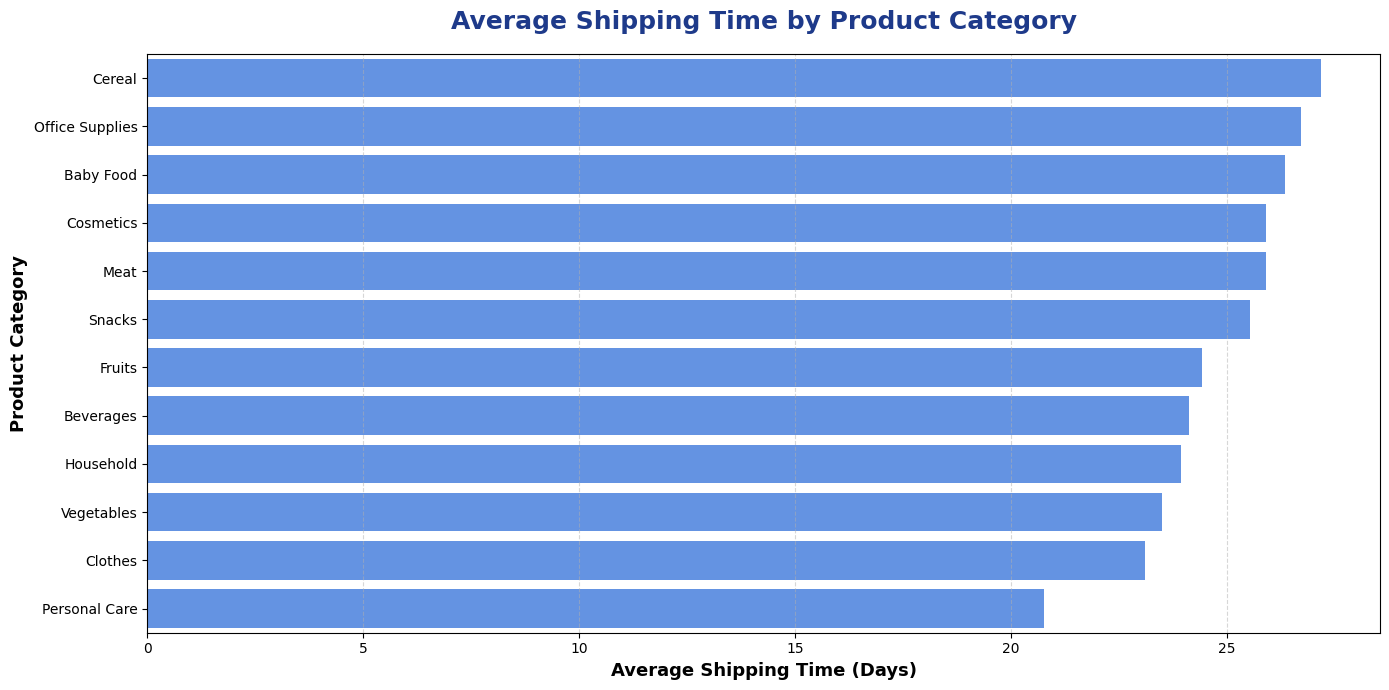

In [ ]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=shipping_by_category,
    x="average_shipping_days",
    y="item_type",
    color="#4F8EF7")

plt.title(
    "Average Shipping Time by Product Category",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

plt.xlabel("Average Shipping Time (Days)", fontsize=13, fontweight="bold")
plt.ylabel("Product Category", fontsize=13, fontweight="bold")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Cereal, Office Supplies, and Baby Food have the highest figures, at around 26–27 units. Personal Care has the lowest result, at approximately 21 units. Overall, the figures for most categories are fairly even and range from 23–27 units, indicating no significant disparities.

###Shipping Interval by Region

In [ ]:
geo_shipping_data = shipping_data[
    (shipping_data["country"] != "Unknown") &
    (shipping_data["region"] != "Unknown")]

shipping_by_region = (
    geo_shipping_data.groupby("region", as_index=False)
    .agg(
        average_shipping_days=("shipping_days", "mean"),
        median_shipping_days=("shipping_days", "median"),
        min_shipping_days=("shipping_days", "min"),
        max_shipping_days=("shipping_days", "max"),
        orders=("order_id", "nunique")
    ).sort_values("average_shipping_days", ascending=False))

shipping_by_region[["average_shipping_days", "median_shipping_days"]] = shipping_by_region[["average_shipping_days", "median_shipping_days"]].round(2)

display(shipping_by_region)

,region,average_shipping_days,median_shipping_days,min_shipping_days,max_shipping_days,orders
0,Asia,26.09,25.5,1,50,82
1,Europe,24.79,25.0,0,50,1164


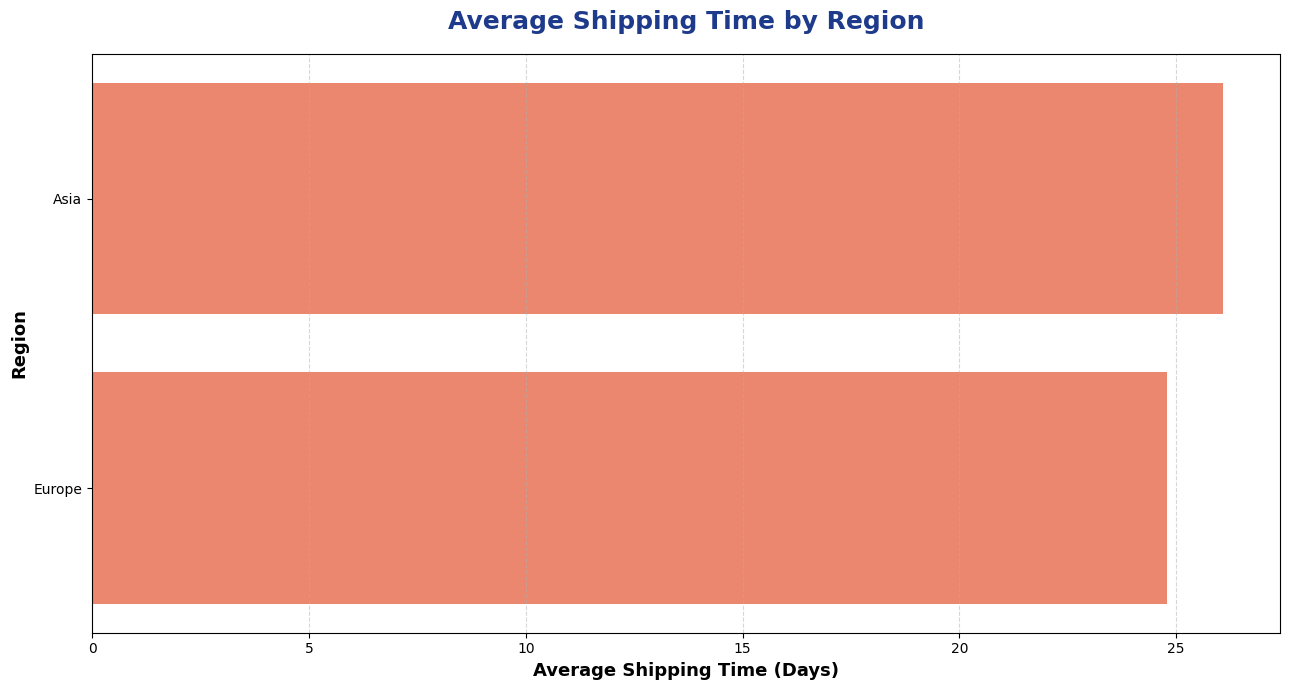

In [ ]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=shipping_by_region,
    x="average_shipping_days",
    y="region",
    color="#FF7A59")

plt.title(
    "Average Shipping Time by Region",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

plt.xlabel("Average Shipping Time (Days)", fontsize=13, fontweight="bold")
plt.ylabel("Region", fontsize=13, fontweight="bold")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The chart shows that the average delivery time to Asia is approximately 26 days, and to Europe about 25 days.

###Shipping Interval by Country

In [ ]:
shipping_by_country = (
    geo_shipping_data.groupby("country", as_index=False)
    .agg(
        average_shipping_days=("shipping_days", "mean"),
        median_shipping_days=("shipping_days", "median"),
        min_shipping_days=("shipping_days", "min"),
        max_shipping_days=("shipping_days", "max"),
        orders=("order_id", "nunique")))


shipping_by_country = shipping_by_country[
    shipping_by_country["orders"] >= 5]

shipping_by_country[
    ["average_shipping_days", "median_shipping_days"]] = shipping_by_country[["average_shipping_days", "median_shipping_days"]].round(2)

slowest_countries = (
    shipping_by_country
    .sort_values("average_shipping_days", ascending=False)
    .head(15)
)

display(slowest_countries)

,country,average_shipping_days,median_shipping_days,min_shipping_days,max_shipping_days,orders
18,Hungary,32.64,36.0,2,50,25
15,Georgia,29.70,32.0,7,47,23
3,Austria,28.50,29.0,3,50,28
38,Slovakia,28.47,32.0,3,50,30
25,Luxembourg,27.75,30.5,0,48,28
24,Lithuania,27.56,30.0,5,49,25
32,Poland,27.46,27.0,6,50,28
35,Russia,27.38,34.0,0,50,32
28,Monaco,26.85,33.0,5,48,13
7,Bulgaria,26.80,26.0,3,48,30


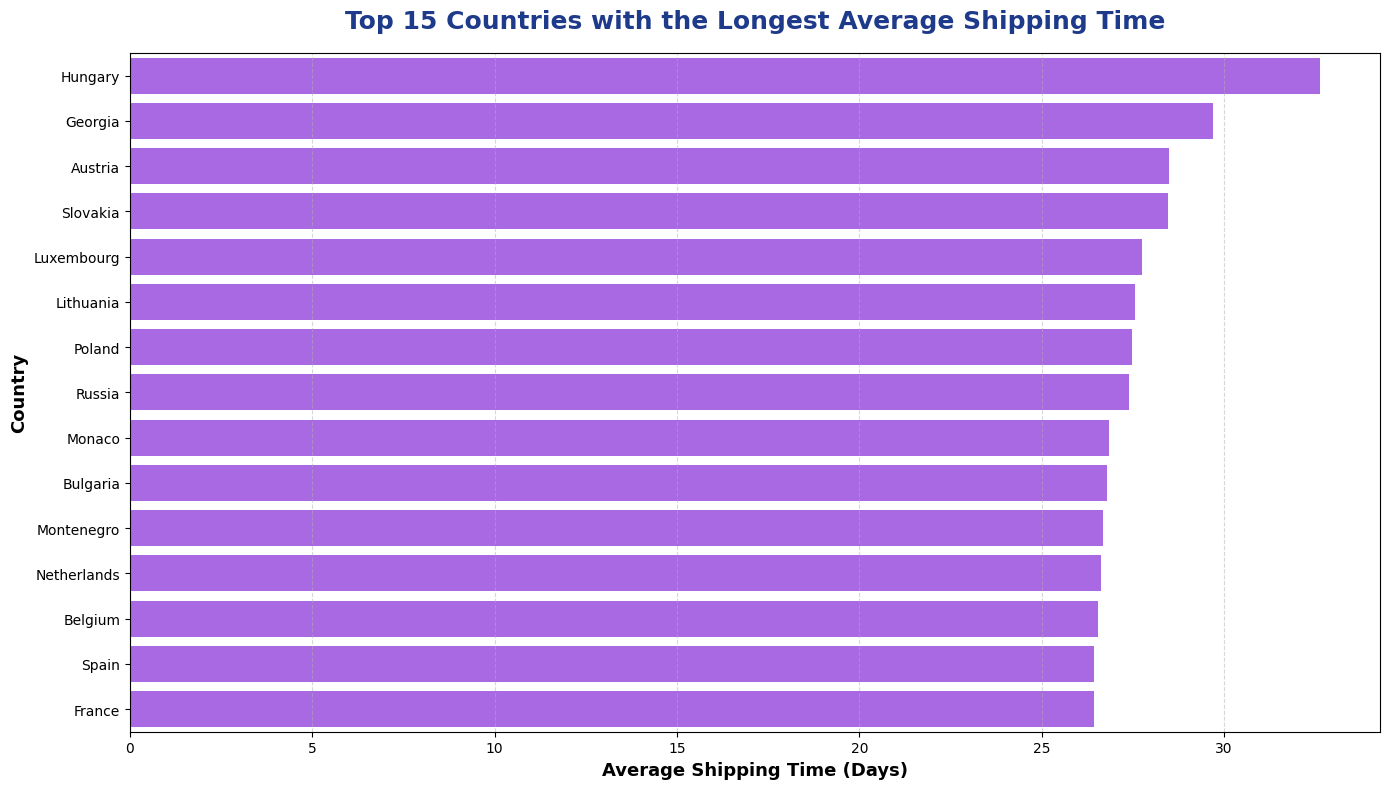

In [ ]:
plt.figure(figsize=(14, 8))

sns.barplot(
    data=slowest_countries,
    x="average_shipping_days",
    y="country",
    color="#A855F7"
)

plt.title(
    "Top 15 Countries with the Longest Average Shipping Time",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18
)

plt.xlabel("Average Shipping Time (Days)", fontsize=13, fontweight="bold")
plt.ylabel("Country", fontsize=13, fontweight="bold")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The chart shows that Hungary has the longest average delivery time, at approximately 34 days. It is followed by Georgia, at about 31 days, and Austria and Slovakia, at about 23–30 days. Spain and France have the lowest figures, at approximately 26–27 days.

###Drawing Key Conclusions

In [ ]:
slowest_category = shipping_by_category.loc[
    shipping_by_category["average_shipping_days"].idxmax()]

fastest_category = shipping_by_category.loc[
    shipping_by_category["average_shipping_days"].idxmin()]

slowest_region = shipping_by_region.loc[
    shipping_by_region["average_shipping_days"].idxmax()]

fastest_region = shipping_by_region.loc[
    shipping_by_region["average_shipping_days"].idxmin()]

slowest_country = shipping_by_country.loc[
    shipping_by_country["average_shipping_days"].idxmax()]

print(
    f"Category with the longest shipping time: "
    f"{slowest_category['item_type']} "
    f"({slowest_category['average_shipping_days']:.2f} days)")

print(
    f"Category with the shortest shipping time: "
    f"{fastest_category['item_type']} "
    f"({fastest_category['average_shipping_days']:.2f} days)")

print(
    f"Region with the longest shipping time: "
    f"{slowest_region['region']} "
    f"({slowest_region['average_shipping_days']:.2f} days)")

print(
    f"Region with the shortest shipping time: "
    f"{fastest_region['region']} "
    f"({fastest_region['average_shipping_days']:.2f} days)")

print(
    f"Country with the longest shipping time: "
    f"{slowest_country['country']} "
    f"({slowest_country['average_shipping_days']:.2f} days)")

Category with the longest shipping time: Cereal (27.18 days)
Category with the shortest shipping time: Personal Care (20.76 days)
Region with the longest shipping time: Asia (26.09 days)
Region with the shortest shipping time: Europe (24.79 days)
Country with the longest shipping time: Hungary (32.64 days)


###Analysis of Shipping Time in Relation to Profit

In [ ]:
profit_by_shipping_days = (
    shipping_data.groupby("shipping_days", as_index=False)
    .agg(
        average_profit=("profit", "mean"),
        total_profit=("profit", "sum"),
        orders=("order_id", "nunique")
        ).sort_values("shipping_days", ascending=False))

display(profit_by_shipping_days)

,shipping_days,average_profit,total_profit,orders
50,50,304252.151905,6389295.19,21
49,49,449198.790400,11229969.76,25
48,48,277767.119643,7777479.35,28
47,47,564746.923636,12424432.32,22
46,46,449214.668462,11679581.38,26
45,45,351263.147083,8430315.53,24
44,44,393351.696875,12587254.30,32
43,43,393550.263333,10625857.11,27
42,42,320388.368500,6407767.37,20
41,41,436604.784762,9168700.48,21


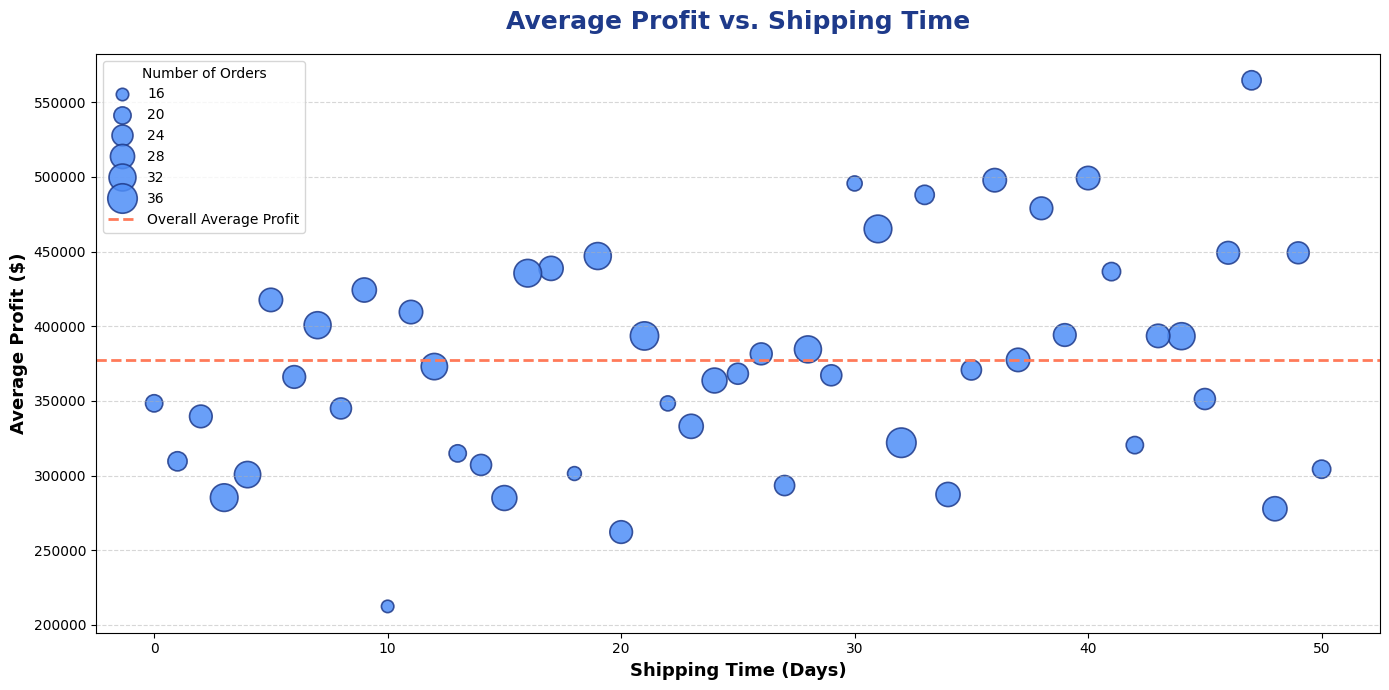

In [ ]:
plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=profit_by_shipping_days,
    x="shipping_days",
    y="average_profit",


    size="orders",
    sizes=(80, 450),

    color="#4F8EF7",
    edgecolor="#1E3A8A",
    linewidth=1.2,
    alpha=0.85)


plt.axhline(
    y=df["profit"].mean(),
    color="#FF7A59",
    linestyle="--",
    linewidth=2,
    label="Overall Average Profit")

plt.title(
    "Average Profit vs. Shipping Time",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

plt.xlabel("Shipping Time (Days)", fontsize=13, fontweight="bold")
plt.ylabel("Average Profit ($)", fontsize=13, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.grid(axis="x", visible=False)

plt.legend(title="Number of Orders")
plt.tight_layout()
plt.show()

The scatter plot does not show a pronounced linear relationship between shipping time and average profit. Average profit varies significantly across almost all delivery intervals: both short and long shipping times include points above and below the overall average.
The average profit across all orders is approximately $375,000, indicated by the dashed line. For shipping times of 30–40 days, values above the average occur more frequently, but this range also includes substantially lower results. For shipping times exceeding 40 days, profit is also unstable, with both high and low values.
Thus, shipping time alone is not the determining factor in profit. Profitability is likely to be more strongly affected by product category, units sold, price, cost, country, and sales channel

###Analysis of Sales Trends over Time by Product Category, Country, and Region

In [ ]:
df["order_month"] = ( df["order_date"].dt.to_period("M").dt.to_timestamp())

top_categories = ( df.groupby("item_type")["revenue"].sum().nlargest(5).index)


monthly_sales_by_category = (
    df[df["item_type"].isin(top_categories)].groupby(["order_month", "item_type"], as_index=False).agg(revenue=("revenue", "sum")).sort_values(["order_month", "item_type"]))

display(monthly_sales_by_category.head())

,order_month,item_type,revenue
0,2010-01-01,Baby Food,4149321.12
1,2010-01-01,Cosmetics,5452321.20
2,2010-02-01,Baby Food,1272060.24
3,2010-02-01,Household,516572.71
4,2010-02-01,Meat,6734630.07


In [ ]:
plt.figure(figsize=(15, 8))

sns.lineplot(
    data=weekday_sales_top5,
    x="order_weekday",
    y="sales_index",
    hue="item_type",
    marker="o",
    linewidth=2.5)

plt.axhline(
    y=100,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Category Average")

plt.title(
    "Monthly Revenue Trends: Top 5 Product Categories",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

plt.xlabel("Day of Week", fontsize=13, fontweight="bold")
plt.ylabel("Sales Index (% of Category Average)", fontsize=13, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.grid(axis="x", visible=False)

plt.legend(
    title="Product Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left")

plt.tight_layout()
plt.show()

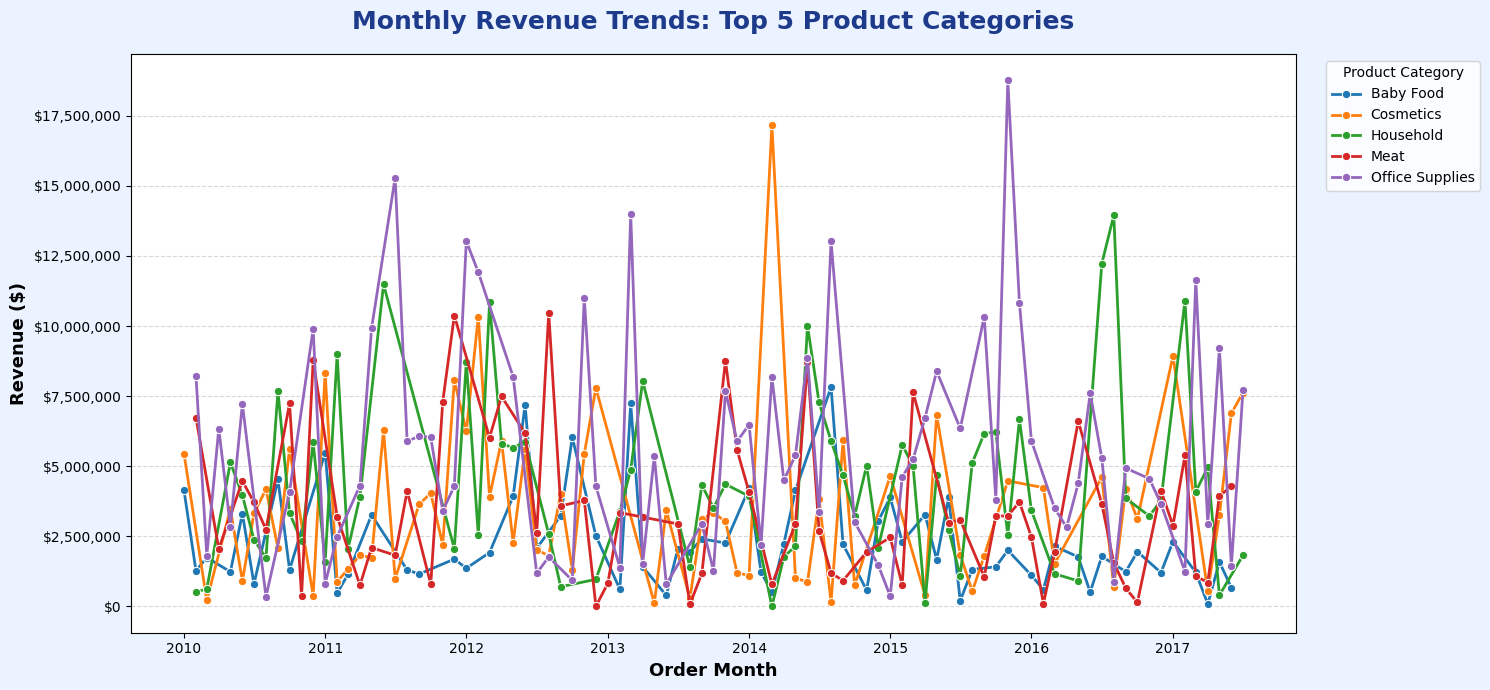

In [ ]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
fig, ax = plt.subplots(figsize=(15, 7))

fig.patch.set_facecolor("#EAF3FF")
ax.set_facecolor("#FFFFFF")

sns.lineplot(
    data=monthly_sales_by_category,
    x="order_month",
    y="revenue",
    hue="item_type",
    marker="o",
    linewidth=2,
    ax=ax)

ax.set_title(
    "Monthly Revenue Trends: Top 5 Product Categories",
    fontsize=18,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

ax.set_xlabel("Order Month", fontsize=13, fontweight="bold")
ax.set_ylabel("Revenue ($)", fontsize=13, fontweight="bold")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}"))

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.grid(axis="x", visible=False)

ax.legend(title="Product Category", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout()
plt.show()


In [ ]:

df["year_quarter"] = df["order_date"].dt.to_period("Q")

quarterly_revenue = (
    df[df["item_type"].isin(top_categories)]
    .groupby(["item_type", "year_quarter"], as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")))

all_quarters = pd.period_range(
    start=df["order_date"].min().to_period("Q"),
    end=df["order_date"].max().to_period("Q"),
    freq="Q")

full_quarter_grid = pd.MultiIndex.from_product(
    [top_categories, all_quarters],
    names=["item_type", "year_quarter"]
).to_frame(index=False)

quarter_sales_by_category = (
    full_quarter_grid.merge(
        quarterly_revenue,
        on=["item_type", "year_quarter"],
        how="left" ).fillna({
        "revenue": 0,
        "orders": 0
    }).sort_values(["item_type", "year_quarter"]))


quarter_sales_by_category["quarter_label"] = (
    quarter_sales_by_category["year_quarter"].astype(str))

display(quarter_sales_by_category.head(10))

print(
    quarter_sales_by_category
    .groupby("item_type")
    .size())

,item_type,year_quarter,revenue,orders,quarter_label
124,Baby Food,2010Q1,7165709.60,5.0,2010Q1
125,Baby Food,2010Q2,4546026.24,3.0,2010Q2
126,Baby Food,2010Q3,5333054.48,6.0,2010Q3
127,Baby Food,2010Q4,1306523.04,1.0,2010Q4
128,Baby Food,2011Q1,7108271.60,5.0,2011Q1
129,Baby Food,2011Q2,3266052.32,2.0,2011Q2
130,Baby Food,2011Q3,2457325.28,2.0,2011Q3
131,Baby Food,2011Q4,1689443.04,1.0,2011Q4
132,Baby Food,2012Q1,3283666.64,3.0,2012Q1
133,Baby Food,2012Q2,11117699.28,7.0,2012Q2


item_type
Baby Food          31
Cosmetics          31
Household          31
Meat               31
Office Supplies    31
dtype: int64


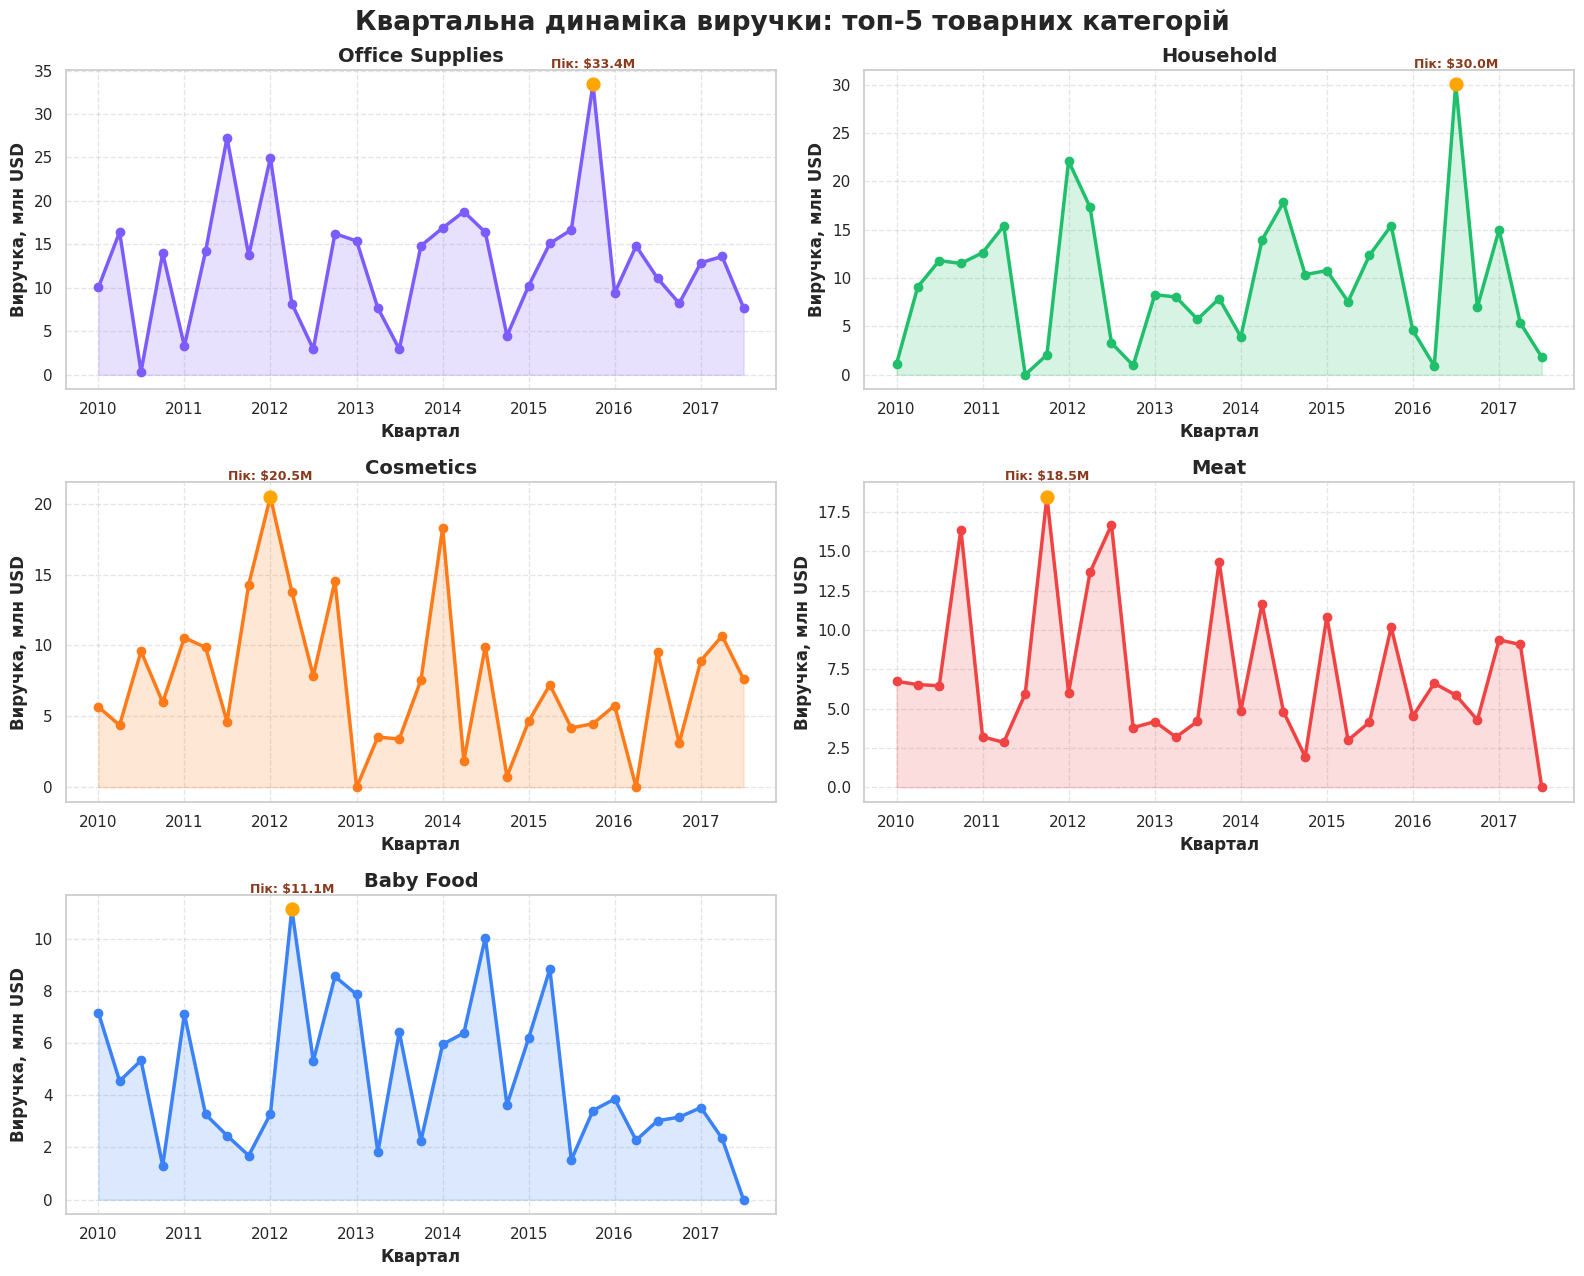

In [ ]:

quarter_sales_by_category["quarter_date"] = (
    quarter_sales_by_category["year_quarter"]
    .dt.to_timestamp())


colors = ["#7C5CFC", "#20BF6B", "#FF7A18", "#F04444", "#3B82F6"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13))
axes = axes.flatten()

for ax, category, color in zip(axes, top_categories, colors):
    category_data = quarter_sales_by_category[
        quarter_sales_by_category["item_type"] == category
    ].sort_values("quarter_date")

    ax.plot(
        category_data["quarter_date"],
        category_data["revenue"] / 1_000_000,
        marker="o",
        linewidth=2.5,
        color=color)

    ax.fill_between(
        category_data["quarter_date"],
        category_data["revenue"] / 1_000_000,
        alpha=0.18,
        color=color)

    ax.set_title(category, fontsize=14, fontweight="bold")
    ax.set_xlabel("Quarter", fontweight="bold")
    ax.set_ylabel("Revenue, USD millions", fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)

    peak = category_data.loc[category_data["revenue"].idxmax()]
    ax.scatter(
        peak["quarter_date"],
        peak["revenue"] / 1_000_000,
        color="#FFA500",
        s=85,
        zorder=5)

    ax.annotate(
        f'Peak: ${peak["revenue"] / 1_000_000:.1f}M',
        xy=(peak["quarter_date"], peak["revenue"] / 1_000_000),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#8B3A1E")

    ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
    ax.xaxis.set_major_formatter(
        plt.matplotlib.dates.DateFormatter("%Y"))

fig.delaxes(axes[-1])

fig.suptitle(
    "Quarterly Revenue Trends: Top 5 Product Categories",
    fontsize=19,
    fontweight="bold",
    y=0.98)

plt.tight_layout()
plt.show()

Conclusion: it is uneven and shows sharp short-term fluctuations. The largest quarterly peak was recorded in Office Supplies: USD 33.4 million at the end of 2015. Other significant peaks include Household at USD 30 million in 2016, Cosmetics at USD 20.5 million in 2012, Meat at USD 18.5 million at the end of 2011, and Baby Food at USD 11.1 million in 2012.
Revenue peaks occur at different times for each category, so no common, stable seasonal pattern is apparent. Revenue is most volatile in Office Supplies and Household, while Baby Food has lower figures and a gradual decline toward the end of the period under review.

In [ ]:

df["order_year"] = df["order_date"].dt.year

top_categories = (
    df.groupby("item_type")["revenue"]
    .sum()
    .nlargest(5)
    .index
    .tolist()
)

annual_revenue = (
    df[df["item_type"].isin(top_categories)]
    .groupby(["item_type", "order_year"], as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")
    )
)


all_years = list(
    range(
        int(df["order_year"].min()),
        int(df["order_year"].max()) + 1
    )
)

full_grid = pd.MultiIndex.from_product(
    [top_categories, all_years],
    names=["item_type", "order_year"]
).to_frame(index=False)

year_sales_by_category = (
    full_grid.merge(
        annual_revenue,
        on=["item_type", "order_year"],
        how="left"
    )
    .fillna({
        "revenue": 0,
        "orders": 0
    })
    .sort_values(["item_type", "order_year"])
)

display(year_sales_by_category.head(10))

print(
    year_sales_by_category
    .groupby("item_type")
    .size()
)

,item_type,order_year,revenue,orders
32,Baby Food,2010,18351313.36,15
33,Baby Food,2011,14521092.24,10
34,Baby Food,2012,28261538.24,18
35,Baby Food,2013,18354887.28,14
36,Baby Food,2014,26004097.20,19
37,Baby Food,2015,19961109.04,15
38,Baby Food,2016,12321599.76,14
39,Baby Food,2017,5871950.56,7
16,Cosmetics,2010,25620357.20,12
17,Cosmetics,2011,39341879.20,17


item_type
Baby Food          8
Cosmetics          8
Household          8
Meat               8
Office Supplies    8
dtype: int64


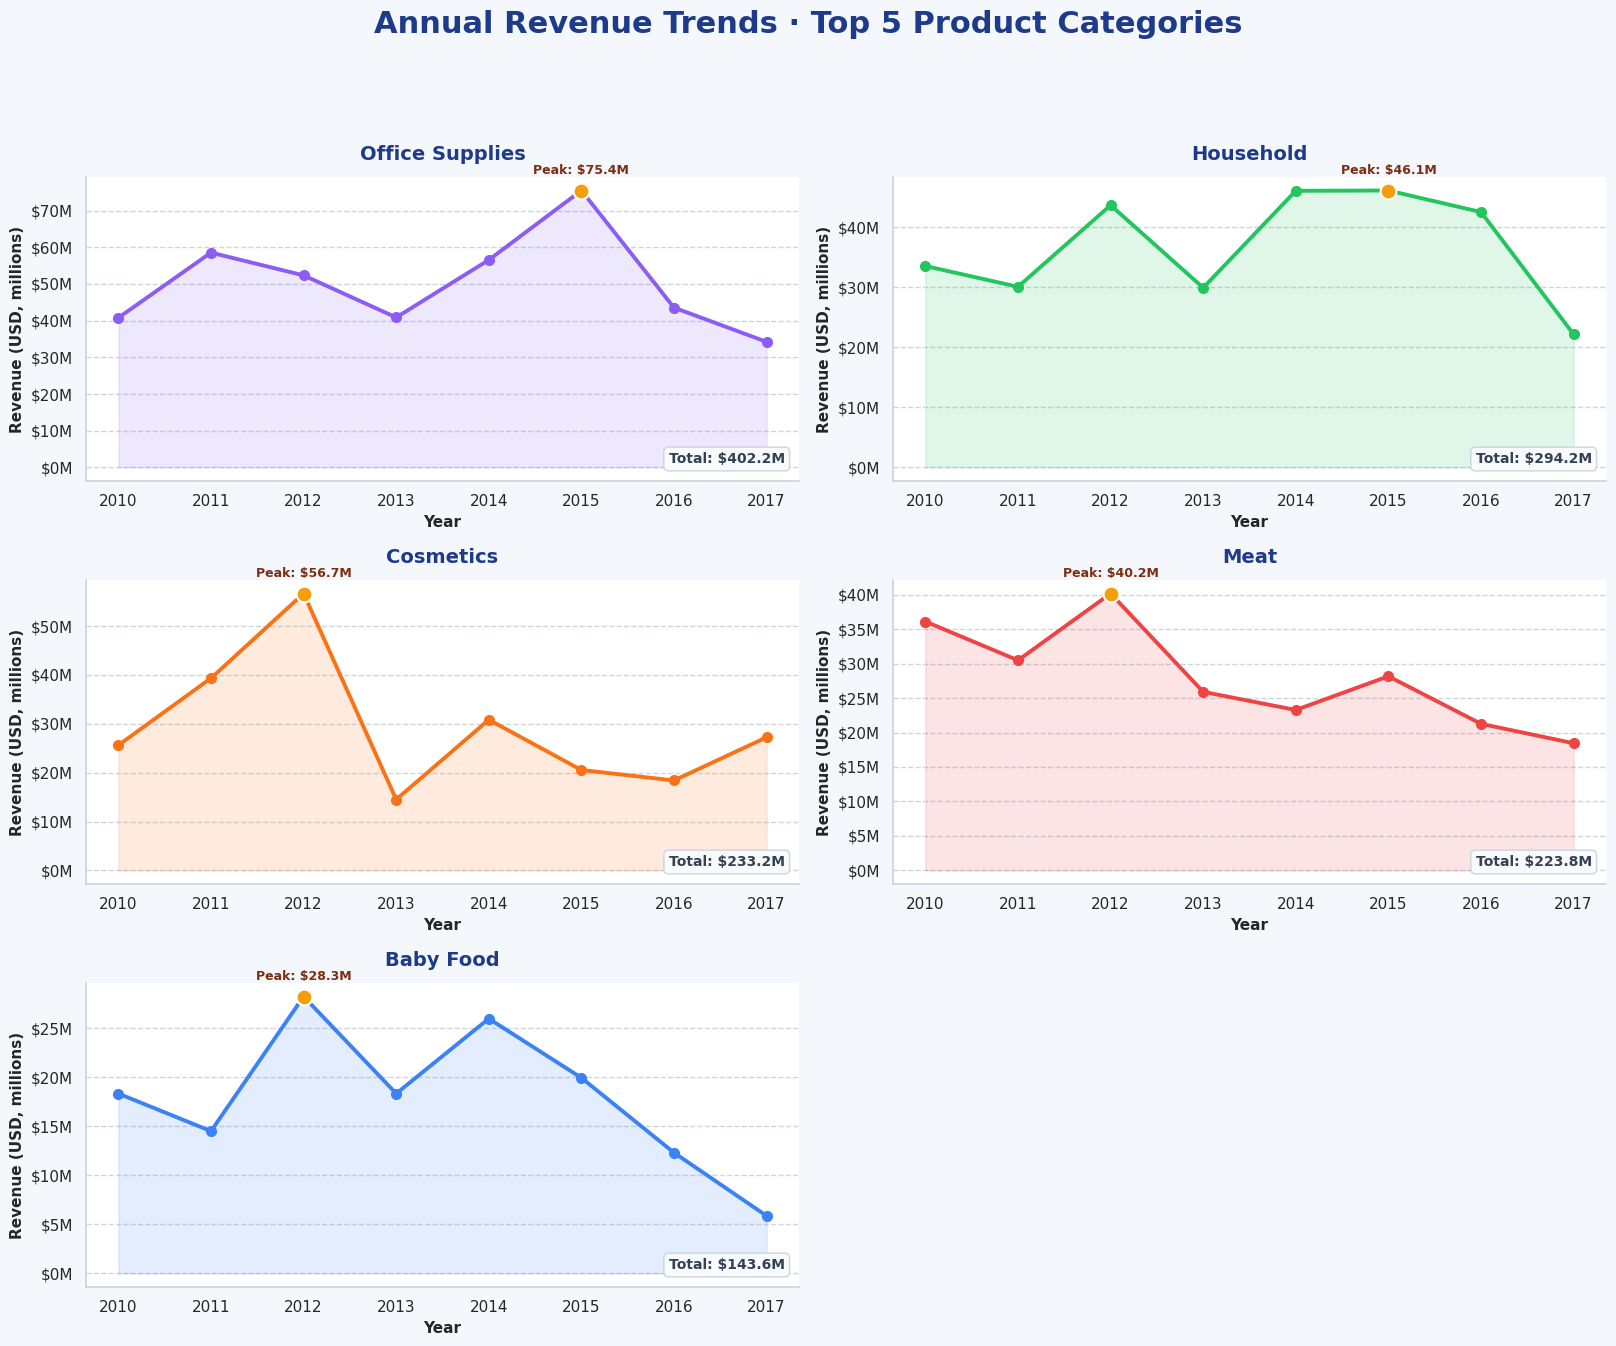

In [ ]:
sns.set_theme(style="whitegrid")

category_colors = {
    "Baby Food": "#3B82F6",
    "Cosmetics": "#F97316",
    "Household": "#22C55E",
    "Meat": "#EF4444",
    "Office Supplies": "#8B5CF6"}

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(17, 14),
    facecolor="#F4F7FB")

axes = axes.flatten()

for ax, category in zip(axes, top_categories):
    category_data = year_sales_by_category[
        year_sales_by_category["item_type"] == category]

    color = category_colors.get(category, "#4F8EF7")

    revenue_millions = category_data["revenue"] / 1_000_000

    ax.plot(
        category_data["order_year"],
        revenue_millions,
        color=color,
        linewidth=2.8,
        marker="o",
        markersize=7)

    ax.fill_between(
        category_data["order_year"],
        revenue_millions,
        color=color,
        alpha=0.14)

    peak_row = category_data.loc[
        category_data["revenue"].idxmax()]

    peak_year = peak_row["order_year"]
    peak_revenue_m = peak_row["revenue"] / 1_000_000

    ax.scatter(
        peak_year,
        peak_revenue_m,
        color="#F59E0B",
        edgecolor="#FFFFFF",
        linewidth=1.5,
        s=130,
        zorder=5)

    ax.annotate(
        f"Peak: ${peak_revenue_m:,.1f}M",
        xy=(peak_year, peak_revenue_m),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#7C2D12")

    ax.set_title(
        category,
        fontsize=14,
        fontweight="bold",
        color="#1E3A8A",
        pad=12)

    ax.set_xlabel("Year", fontsize=11, fontweight="bold")
    ax.set_ylabel("Revenue (USD, millions)", fontsize=11, fontweight="bold")

    ax.set_xticks(all_years)

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, position: f"${value:,.0f}M"))

    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", linestyle="--", alpha=0.45, color="#94A3B8")
    ax.grid(axis="x", visible=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

    total_category_revenue = category_data["revenue"].sum() / 1_000_000

    ax.text(
        0.98,
        0.05,
        f"Total: ${total_category_revenue:,.1f}M",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#334155",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#F8FAFC",
            edgecolor="#CBD5E1"))

for ax in axes[len(top_categories):]:
    ax.set_visible(False)


fig.suptitle(
    "Annual Revenue Trends · Top 5 Product Categories",
    fontsize=22,
    fontweight="bold",
    color="#1E3A8A",
    y=0.98)

fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.93])
plt.show()

In 2010–2017, revenue across the five product categories fluctuated, with the highest figures occurring in different years: Office Supplies at USD 75.4 million, Cosmetics at USD 56.7 million, Household at USD 46.1 million, Meat at USD 40.2 million, and Baby Food at USD 28.3 million. Office Supplies generated the highest total revenue at USD 402.2 million, while Baby Food had the lowest total among the categories shown, at USD 143.6 million.

###Analysis of Product Sales by Day of the Week

In [ ]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"]

df["order_weekday"] = pd.Categorical(
    df["order_date"].dt.day_name(),
    categories=day_order,
    ordered=True)

weekday_sales = (
    df.groupby(
        ["item_type", "order_weekday"],
        observed=False,
        as_index=False)
    .agg(revenue=("revenue", "sum"),orders=("order_id", "nunique")))

weekday_sales["average_category_day_revenue"] = (
    weekday_sales
    .groupby("item_type")["revenue"]
    .transform("mean"))

weekday_sales["sales_index"] = (
    weekday_sales["revenue"] /
    weekday_sales["average_category_day_revenue"] *
    100)

top_categories = (
    df.groupby("item_type")["revenue"]
    .sum()
    .nlargest(5)
    .index)

weekday_sales_top5 = weekday_sales[
    weekday_sales["item_type"].isin(top_categories)
].copy()

display(weekday_sales_top5.head())

,item_type,order_weekday,revenue,orders,average_category_day_revenue,sales_index
0,Baby Food,Monday,15600926.64,17,2.052108e+07,76.023892
1,Baby Food,Tuesday,21812654.88,16,2.052108e+07,106.293873
2,Baby Food,Wednesday,20737670.80,16,2.052108e+07,101.055436
3,Baby Food,Thursday,18823581.36,13,2.052108e+07,91.728007
4,Baby Food,Friday,20200051.12,16,2.052108e+07,98.435595


Analysis of monthly, quarterly, and annual revenue showed that sales in the top-5 product categories fluctuated. In the annual analysis, Office Supplies generated the highest total revenue at USD 402.2 million, while Baby Food had the lowest total among the categories analyzed at USD 143.6 million. The highest annual figures were also observed in Office Supplies, Cosmetics, Household, and Meat, but they occurred in different years.
The monthly analysis revealed significant short-term fluctuations in revenue: the largest monthly peak was recorded in Office Supplies at almost USD 19 million in 2015. The quarterly analysis provided more detail on these changes: the highest quarterly revenue also belonged to Office Supplies, reaching USD 33.4 million at the end of 2015. Significant quarterly peaks were also recorded in Household at USD 30 million, Cosmetics at USD 20.5 million, Meat at USD 18.5 million, and Baby Food at USD 11.1 million.

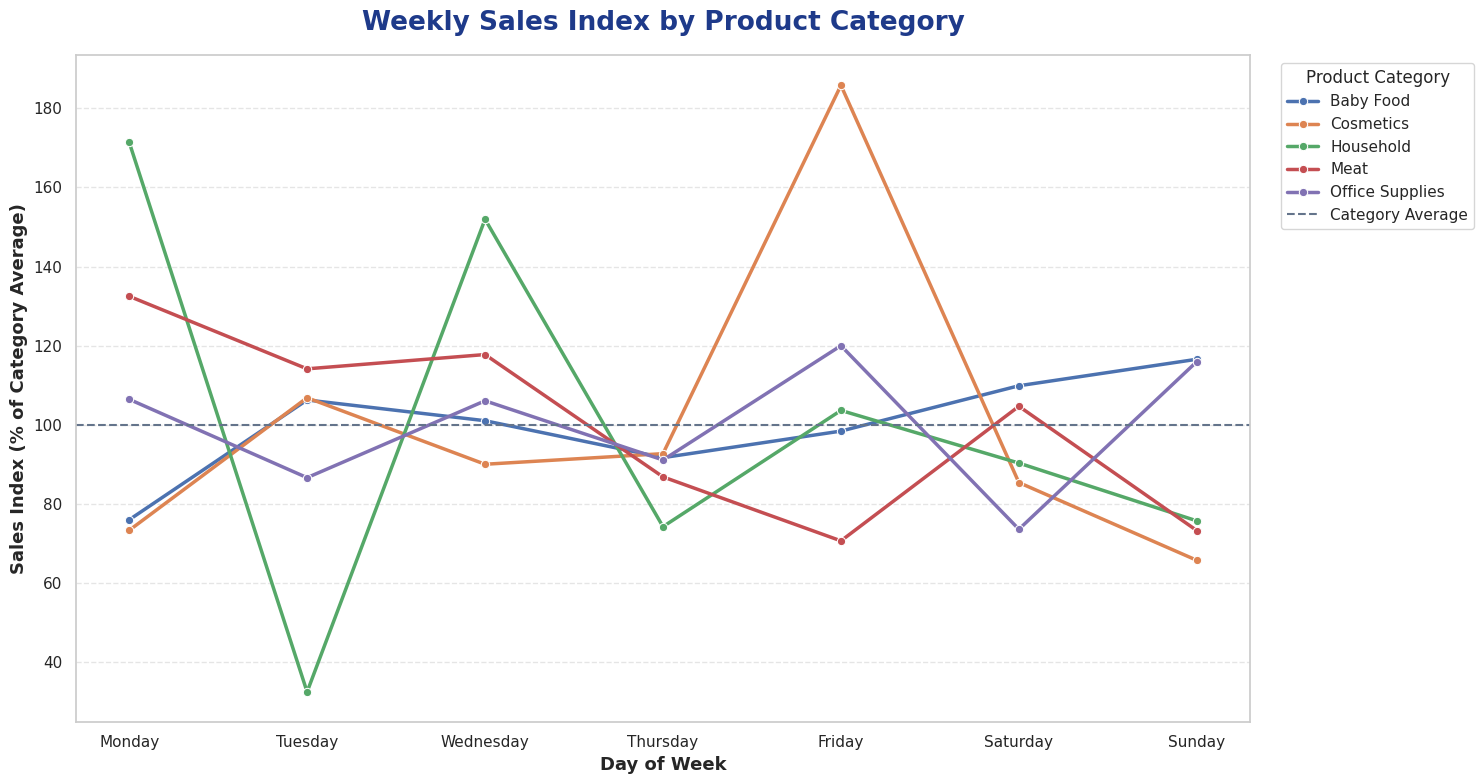

In [ ]:
plt.figure(figsize=(15, 8))

sns.lineplot(
    data=weekday_sales_top5,
    x="order_weekday",
    y="sales_index",
    hue="item_type",
    marker="o",
    linewidth=2.5)

plt.axhline(
    y=100,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Category Average")

plt.title(
    "Weekly Sales Index by Product Category",
    fontsize=19,
    fontweight="bold",
    color="#1E3A8A",
    pad=18)

plt.xlabel("Day of Week", fontsize=13, fontweight="bold")
plt.ylabel("Sales Index (% of Category Average)", fontsize=13, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.grid(axis="x", visible=False)

plt.legend(
    title="Product Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left")

plt.tight_layout()
plt.show()

Analysis of the sales index by day of the week showed that some product categories have pronounced weekly cycles. The strongest fluctuations occur in Cosmetics and Household.
Cosmetics has its highest sales index on Friday, at around 186%, meaning that its revenue on this day is approximately 86% above the average daily level. On Sunday, the index falls to approximately 66%. This indicates that cosmetics sales vary considerably by day of the week. Household also shows significant fluctuations: its highest sales occur on Monday (+-171%) and Wednesday (+-152%), while the figure falls to (+-32%) on Tuesday. This is the most pronounced weekly pattern among the categories shown.

Meat sales are higher at the beginning of the week, especially on Monday (+-132%), and lower on Friday and Sunday. Office Supplies shows moderate variation: its peaks occur on Friday (+-120%) and Sunday (+-115%), while its lowest level is on Saturday (+-73%). Baby Food has the most stable pattern: most values are close to the average, although sales are slightly higher on weekends. Thus, Cosmetics and Household can be considered categories with pronounced weekly cycles

#Conclusions from a Business Perspective


- Office Supplies is the main driver of turnover, with USD 402.2 million in revenue and 617.6 thousand units sold. At the same time, the category has a relatively low profit margin of around 19%.
- Cosmetics has the highest profit at USD 92.7 million and a high profit margin of approximately 40%. This makes it the most promising category for marketing promotion, assortment expansion, and prioritized inventory management.
- Meat generates substantial revenue but has the lowest profitability among the key categories, at around 14%. Costs, supplier terms, and pricing policy should be reviewed
- Most revenue is concentrated in Europe: USD 1.51 billion in revenue and USD 448.6 million in profit. This is a strong position, but it also creates a risk of dependence on one region. Asia has lower volumes, so it is reasonable to consider it as a direction for cautious expansion.
- The offline channel only slightly exceeds the online channel in profit: USD 253.5 million versus USD 248.0 million. Therefore, the focus should not shift solely to offline; it is more effective to develop both channels and conduct analysis
- Average delivery time is 21–27 days, with the longest delivery time to Hungary at 32.6 days. For Office Supplies, the category with the highest turnover, reducing delivery times could improve customer loyalty and repeat sales. At the same time, the data does not show a clear relationship between delivery time and profit.
- Monthly, quarterly, and annual analysis shows sharp revenue fluctuations without a single seasonal pattern across all categories. Inventory, advertising budgets, and sales plans should therefore be developed separately for each category, taking its quarterly peaks into account